In [66]:
import pandas as pd
import numpy as np

1.1 Знакомство с данными

In [67]:
df = pd.read_csv('real_estate_data.csv', low_memory=False)

In [68]:
print("Размерность данных:", df.shape)

Размерность данных: (403487, 17)


In [69]:
print("\nИнформация о столбцах:")
df.info()


Информация о столбцах:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 403487 entries, 0 to 403486
Data columns (total 17 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 403487 non-null  int64  
 1   type               403487 non-null  object 
 2   sub_type           403487 non-null  object 
 3   start_date         403487 non-null  object 
 4   end_date           266298 non-null  object 
 5   listing_type       403487 non-null  int64  
 6   tom                403487 non-null  int64  
 7   building_age       376097 non-null  object 
 8   total_floor_count  375466 non-null  object 
 9   floor_no           368191 non-null  object 
 10  room_count         403487 non-null  object 
 11  size               257481 non-null  float64
 12  address            403487 non-null  object 
 13  furnished          0 non-null       float64
 14  heating_type       375517 non-null  object 
 15  price              402772 n

In [70]:
print("\nПервые 5 строк:")
print(df.head())


Первые 5 строк:
   id   type  sub_type start_date  end_date  listing_type  tom building_age  \
0   1  Konut  Rezidans   12/10/18    1/9/19             2   30            0   
1   2  Konut     Daire    2/13/19       NaN             1   14            0   
2   3  Konut     Daire    10/9/18   11/8/18             1   30            0   
3   4  Konut  Rezidans    9/10/18  10/10/18             1   30            3   
4   5  Konut  Rezidans   12/10/18    1/9/19             1   30            0   

  total_floor_count      floor_no room_count   size  \
0       20 ve üzeri             2        2+1   90.0   
1       20 ve üzeri   20 ve üzeri        1+0   43.0   
2                 1  Yüksek Giriş        2+1    NaN   
3       20 ve üzeri   20 ve üzeri        6+1  450.0   
4       20 ve üzeri             2        2+1   90.0   

                      address  furnished heating_type       price  \
0  İstanbul/Kartal/Kordonboyu        NaN      Fancoil      3500.0   
1  İstanbul/Kartal/Kordonboyu        Na

In [71]:
print("\nПоследние 5 строк:")
print(df.tail())


Последние 5 строк:
            id   type sub_type start_date end_date  listing_type  tom  \
403482  403483  Konut    Daire    9/18/18      NaN             2  162   
403483  403484  Konut    Daire   10/11/18      NaN             1  139   
403484  403485  Konut    Daire   11/22/18      NaN             1   97   
403485  403486  Konut    Daire    2/21/19      NaN             2    6   
403486  403487  Konut    Daire    1/15/19  1/18/19             1    3   

       building_age total_floor_count floor_no room_count   size  \
403482          NaN               NaN      NaN          +    NaN   
403483          NaN               NaN      NaN        2+1    NaN   
403484          NaN               NaN      NaN        1+1    NaN   
403485          NaN               NaN      NaN        2+1    2.0   
403486          NaN               NaN      NaN        3+1  140.0   

                             address  furnished heating_type     price  \
403482     İstanbul/Sultanbeyli/Adil        NaN          N

In [72]:
print("\nСлучайная строка:")
print(df.sample(1))


Случайная строка:
            id   type sub_type start_date end_date  listing_type  tom  \
155633  155634  Konut    Daire    12/8/18   2/8/19             1   62   

       building_age total_floor_count floor_no room_count   size  \
155633  16-20 arası       10-20 arası        1        3+1  130.0   

                          address  furnished      heating_type     price  \
155633  İstanbul/Beylikdüzü/Barış        NaN  Kombi (Doğalgaz)  460000.0   

       price_currency  
155633            TRY  


1.2 Описательная статистика

In [73]:
print("Описательная статистика для числовых признаков:")
print(df.describe())

Описательная статистика для числовых признаков:
                 id   listing_type            tom           size  furnished  \
count  403487.00000  403487.000000  403487.000000  257481.000000        0.0   
mean   201744.00000       1.294235      57.022739     279.349094        NaN   
std    116476.80837       0.467733      44.358933    9429.195331        NaN   
min         1.00000       1.000000       0.000000       1.000000        NaN   
25%    100872.50000       1.000000      29.000000      85.000000        NaN   
50%    201744.00000       1.000000      40.000000     110.000000        NaN   
75%    302615.50000       2.000000      90.000000     140.000000        NaN   
max    403487.00000       3.000000     180.000000  948235.000000        NaN   

              price  
count  4.027720e+05  
mean   3.546417e+05  
std    4.809503e+06  
min   -2.500000e+02  
25%    2.500000e+03  
50%    1.990000e+05  
75%    3.420000e+05  
max    2.000000e+09  


In [74]:
print("--- Анализ целевой переменной 'price' ---")
print("Среднее значение цены:", df['price'].mean())
print("Медианное значение цены:", df['price'].median())
print("Асимметрия (skewness) цены:", df['price'].skew())

--- Анализ целевой переменной 'price' ---
Среднее значение цены: 354641.66193280567
Медианное значение цены: 199000.0
Асимметрия (skewness) цены: 308.50702657456833


In [75]:
print("Частота категорий в столбце 'type' (тип недвижимости):")
print(df['type'].value_counts())

Частота категорий в столбце 'type' (тип недвижимости):
type
Konut    403487
Name: count, dtype: int64


In [76]:
print("Топ-10 самых частых категорий в столбце 'room_count' (планировка):")
print(df['room_count'].value_counts().head(10))

Топ-10 самых частых категорий в столбце 'room_count' (планировка):
room_count
3+1    157363
2+1    138677
1+1     39134
4+1     37472
5+1      8219
4+2      4540
5+2      2926
+        2898
3+2      2673
1+0      2612
Name: count, dtype: int64


In [77]:
print("Топ-5 самых частых категорий в столбце 'heating_type' (тип отопления):")
print(df['heating_type'].value_counts().head(5))

Топ-5 самых частых категорий в столбце 'heating_type' (тип отопления):
heating_type
Kombi (Doğalgaz)                   204150
Klima                               68197
Merkezi Sistem (Isı Payı Ölçer)     30595
Merkezi Sistem                      22855
Kalorifer (Doğalgaz)                10928
Name: count, dtype: int64


1.3 Визуальный анализ

In [78]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

Text(0, 0.5, 'Количество объектов')

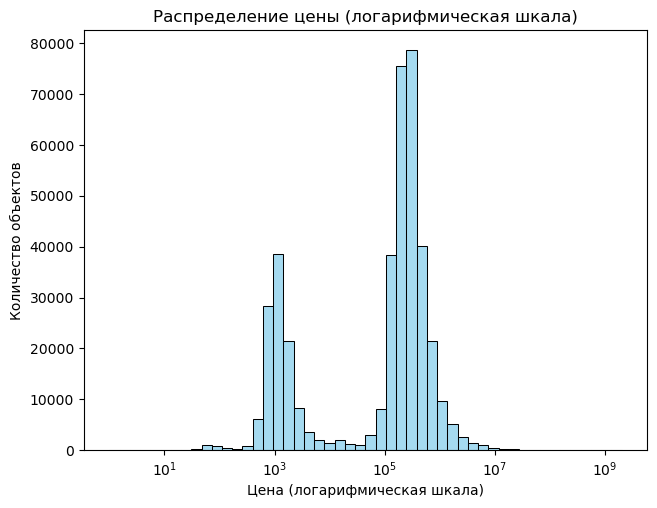

In [79]:
plt.figure(figsize=(16, 12))
plt.subplot(2, 2, 1)
sns.histplot(df['price'].dropna(), bins=50, log_scale=True, color='skyblue')
plt.title('Распределение цены (логарифмическая шкала)')
plt.xlabel('Цена (логарифмическая шкала)')
plt.ylabel('Количество объектов')

(0.0, 2000000.0)

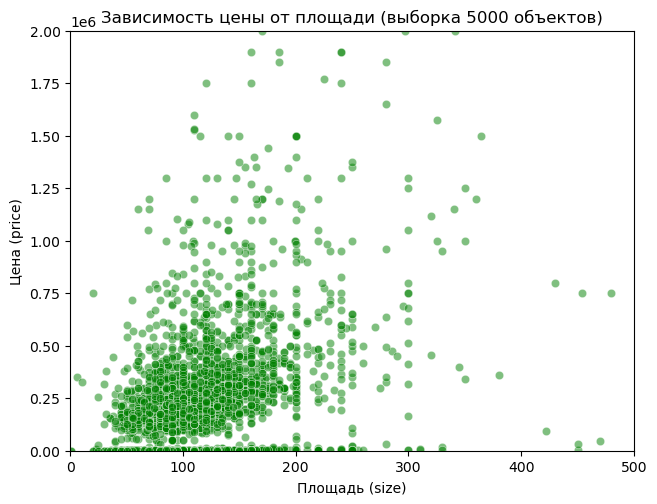

In [80]:
plt.figure(figsize=(16, 12))
df_sample = df.sample(5000, random_state=42)
plt.subplot(2, 2, 2)
sns.scatterplot(data=df_sample, x='size', y='price', alpha=0.5, color='green')
plt.title('Зависимость цены от площади (выборка 5000 объектов)')
plt.xlabel('Площадь (size)')
plt.ylabel('Цена (price)')

plt.xlim(0, 500)
plt.ylim(0, 2000000)

([0, 1, 2, 3, 4],
 [Text(0, 0, '2+1'),
  Text(1, 0, '1+1'),
  Text(2, 0, '3+1'),
  Text(3, 0, '4+1'),
  Text(4, 0, '5+1')])

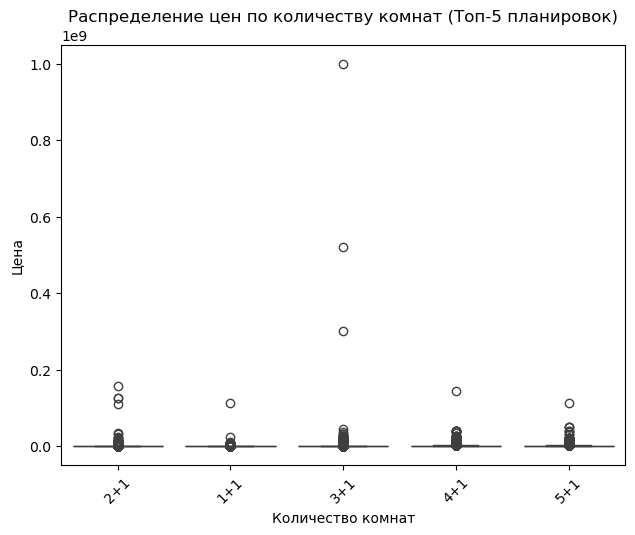

In [81]:
plt.figure(figsize=(16, 12))
plt.subplot(2, 2, 3)
top_rooms = df['room_count'].value_counts().head(5).index
df_rooms = df[df['room_count'].isin(top_rooms)]
sns.boxplot(data=df_rooms, x='room_count', y='price')
plt.title('Распределение цен по количеству комнат (Топ-5 планировок)')
plt.xlabel('Количество комнат')
plt.ylabel('Цена')

plt.xticks(rotation=45)

Text(0.5, 1.0, 'Тепловая карта корреляций числовых признаков')

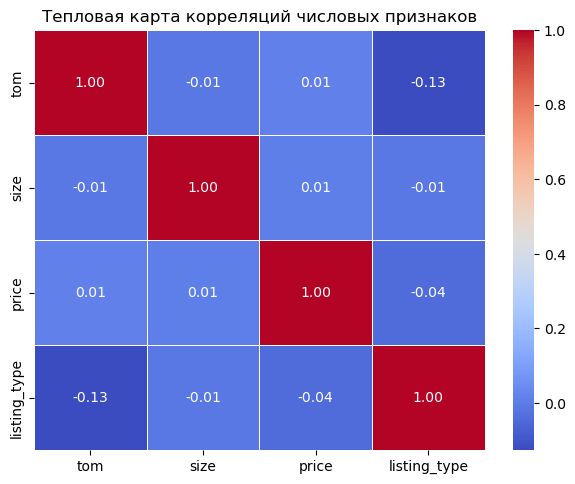

In [82]:
plt.figure(figsize=(16, 12))
plt.subplot(2, 2, 4)
numeric_cols = ['tom', 'size', 'price', 'listing_type']

corr_matrix = df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Тепловая карта корреляций числовых признаков')

Text(0, 0.5, 'Тип отопления')

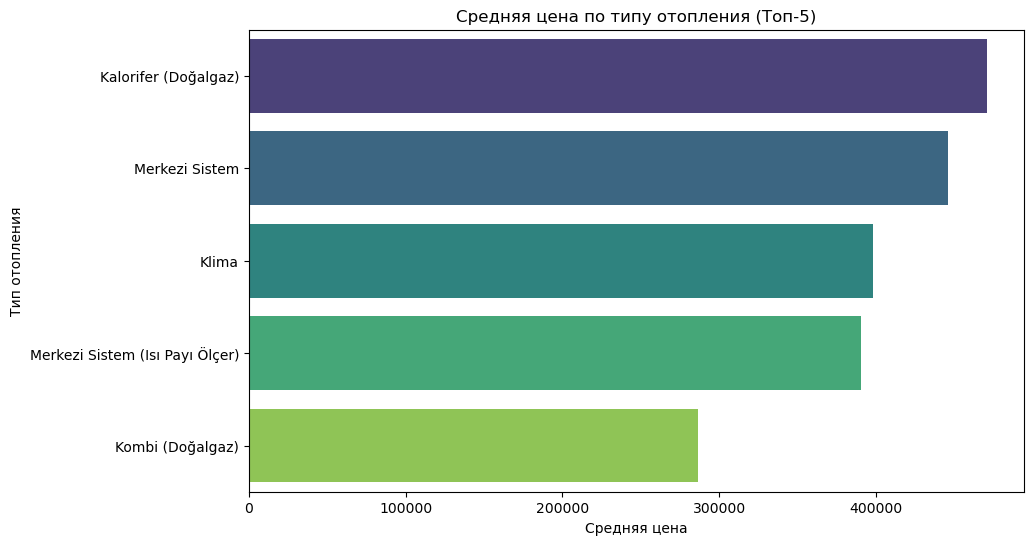

In [83]:
top_heating = df['heating_type'].value_counts().head(5).index
df_heating = df[df['heating_type'].isin(top_heating)]

avg_price_heating = df_heating.groupby('heating_type')['price'].mean().sort_values(ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(x=avg_price_heating.values, y=avg_price_heating.index, palette='viridis', hue=avg_price_heating.index)
plt.title('Средняя цена по типу отопления (Топ-5)')
plt.xlabel('Средняя цена')
plt.ylabel('Тип отопления')

1.4 Анализ пропусков и аномалий

In [84]:
# 1. Анализ пропусков
# Считаем количество пропусков в каждом столбце
missing_values = df.isnull().sum()

# Считаем процент пропусков относительно общего числа строк
missing_percent = (df.isnull().sum() / len(df)) * 100

# Собираем в одну таблицу для удобства
missing_df = pd.DataFrame({
    'Количество пропусков': missing_values,
    'Процент пропусков': missing_percent
})

# Выводим только те столбцы, где есть хотя бы один пропуск
print("Таблица пропусков (только столбцы с NaN):")
print(missing_df[missing_df['Количество пропусков'] > 0])

Таблица пропусков (только столбцы с NaN):
                   Количество пропусков  Процент пропусков
end_date                         137189          34.000848
building_age                      27390           6.788323
total_floor_count                 28021           6.944709
floor_no                          35296           8.747742
size                             146006          36.186048
furnished                        403487         100.000000
heating_type                      27970           6.932070
price                               715           0.177205
price_currency                      715           0.177205


In [85]:
# 2. Проверка на дубликаты
duplicates_count = df.duplicated().sum()
print(f"Количество полных дубликатов строк: {duplicates_count}")

Количество полных дубликатов строк: 0


In [86]:
# 3. Поиск логических аномалий в числовых данных

# А) Отрицательная цена
negative_price = df[df['price'] < 0]
print(f"Количество записей с отрицательной ценой: {len(negative_price)}")
if len(negative_price) > 0:
    print("Примеры строк с отрицательной ценой:")
    print(negative_price[['id', 'price', 'size']].head())

# Б) Нереалистичная площадь
unrealistic_size = df[df['size'] > 1000]
print(f"\nКоличество записей с площадью более 1000 кв.м: {len(unrealistic_size)}")

# В) Проверка столбца building_age (возраст здания)
# Так как тип данных object, там могут быть строки вроде "0", "1-5", "10+ и тд"
print("\nУникальные значения в столбце 'building_age' (первые 20):")
print(df['building_age'].unique()[:20])

Количество записей с отрицательной ценой: 1
Примеры строк с отрицательной ценой:
            id  price  size
350367  350368 -250.0  95.0

Количество записей с площадью более 1000 кв.м: 683

Уникальные значения в столбце 'building_age' (первые 20):
['0' '3' '2' nan '1' '6-10 arası' '4' '16-20 arası' '26-30 arası'
 '40 ve üzeri' '11-15 arası' '21-25 arası' '5' '31-35 arası' '36-40 arası']


1.5 Промежуточные выводы

### Сформулированные гипотезы

## 1. Гипотеза о площади (size):

Изначально корреляция между площадью и ценой близка к нулю (0.01) из-за наличия экстремальных выбросов (683 объекта с площадью > 1000 кв.м) и большого количества пропусков (36%).

Гипотеза: После удаления аномальных значений и корректного заполнения пропусков, площадь станет основным положительным предиктором цены (чем больше площадь, тем выше цена).

## 2. Гипотеза о локации (address):

В данных присутствуют разные районы (например, престижный Beşiktaş/Levent и более удаленный Çorlu).
Гипотеза: Район расположения (извлеченный из столбца address) оказывает сильное влияние на стоимость. Объекты в центральных или деловых районах будут иметь статистически значимую премию к цене по сравнению с пригородами, даже при одинаковой площади.

## 3. Гипотеза о возрасте здания (building_age):

Данные содержат категории от "0" (новостройка) до "40 ve üzeri" (40 лет и более).
Гипотеза: Новые здания (возраст 0–5 лет) будут стоить в среднем дороже, чем старые ("40 ve üzeri"), из-за современных стандартов строительства и отсутствия необходимости в капитальном ремонте. Зависимость, вероятно, будет нелинейной (резкое падение цены после первых 5-10 лет, затем стабилизация).

## 4. Гипотеза о планировке (room_count):

Гипотеза: Количество комнат имеет положительную корреляцию с ценой, но прирост стоимости нелинеен. Переход от студии (1+0) к стандартной квартире (2+1) дает больший абсолютный прирост цены, чем переход от 3+1 к 4+1, так как спрос на массовом рынке сосредоточен именно на 1+1 и 2+1.

# 2.1 РАБОТА С ПРОПУСКАМИ

In [93]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, RobustScaler, StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from statsmodels.stats.outliers_influence import variance_inflation_factor
df = pd.read_csv('real_estate_data.csv', low_memory=False)
print("Исходная размерность:", df.shape)
print("2.1 РАБОТА С ПРОПУСКАМИ")
# Удаляем столбцы
df = df.drop(columns=['furnished', 'end_date'])
# Удаляем строки с пропуском в цене (и валюте)
df = df.dropna(subset=['price', 'price_currency'])
# Заполняем size медианой по room_count (группировка)
df['size'] = df.groupby('room_count')['size'].transform(
    lambda x: x.fillna(x.median())
)
# Если в какой-то группе медиана NaN (мало данных) — общая медиана
df['size'] = df['size'].fillna(df['size'].median())
# Заполняем категориальные модой
for col in ['building_age', 'total_floor_count', 'floor_no', 'heating_type']:
    df[col] = df[col].fillna(df[col].mode()[0])
print("После обработки пропусков:", df.shape)
print("Остаточные пропуски:", df.isnull().sum().sum())

Исходная размерность: (403487, 17)
2.1 РАБОТА С ПРОПУСКАМИ
После обработки пропусков: (402772, 15)
Остаточные пропуски: 0


# 2.2 ОБРАБОТКА ВЫБРОСОВ

2.2 ОБРАБОТКА ВЫБРОСОВ


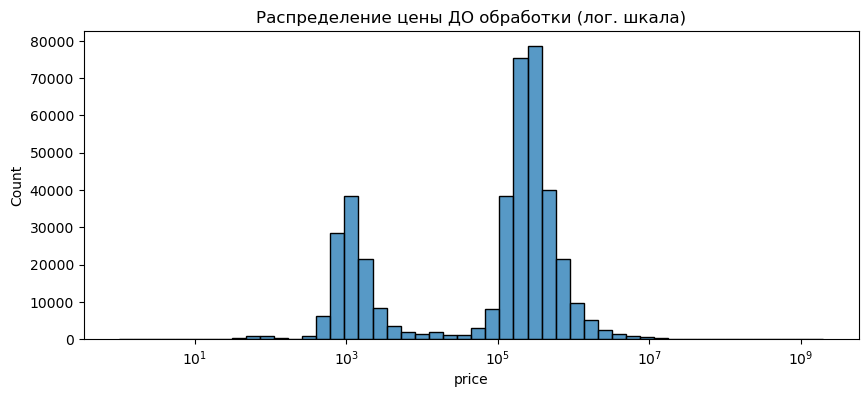

Skewness цены: 308.51
Мин. цена: -250.0, Макс. цена: 2000000000.0

После обработки:
Skewness цены: 3.76
Skewness log(price): -0.81
Размер price: [500, 2850000]
Размер size: [40.0, 380.0]


In [94]:
print("2.2 ОБРАБОТКА ВЫБРОСОВ")
plt.figure(figsize=(10, 4))
sns.histplot(df['price'], bins=50, log_scale=True)
plt.title('Распределение цены ДО обработки (лог. шкала)')
plt.show()
print(f"Skewness цены: {df['price'].skew():.2f}")
print(f"Мин. цена: {df['price'].min()}, Макс. цена: {df['price'].max()}")
# Удаляем отрицательную цену
df = df[df['price'] > 0]
# Винзоризация price и size по 1-му и 99-му перцентилям
def winsorize(series, lower=0.01, upper=0.99):
    lower_bound = series.quantile(lower)
    upper_bound = series.quantile(upper)
    return series.clip(lower=lower_bound, upper=upper_bound)
df['price'] = winsorize(df['price'])
df['size'] = winsorize(df['size'])
# Логарифмирование цены (для нормализации распределения)
df['price_log'] = np.log1p(df['price'])
# Проверяем результат
print(f"\nПосле обработки:")
print(f"Skewness цены: {df['price'].skew():.2f}")
print(f"Skewness log(price): {df['price_log'].skew():.2f}")
print(f"Размер price: [{df['price'].min():.0f}, {df['price'].max():.0f}]")
print(f"Размер size: [{df['size'].min():.1f}, {df['size'].max():.1f}]")


# 2.3 КОДИРОВАНИЕ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ

In [95]:
print("2.3 КОДИРОВАНИЕ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ")
# 1. Извлекаем район из address (последняя часть после /)
df['district'] = df['address'].apply(lambda x: x.split('/')[-1] if pd.notna(x) else 'Unknown')
df = df.drop(columns=['address'])
print(f"Всего уникальных районов: {df['district'].nunique()}")
# 2. Порядковое кодирование room_count
room_order = [['1+0', '1+1', '2+1', '2+2', '3+1', '3+2', '4+1', '4+2', '5+1', '5+2', '+']]
# Оставляем только встречающиеся категории
existing_rooms = [r for r in room_order[0] if r in df['room_count'].unique()]
room_order = [existing_rooms]
room_encoder = OrdinalEncoder(categories=room_order, handle_unknown='use_encoded_value', unknown_value=-1)
df['room_count_enc'] = room_encoder.fit_transform(df[['room_count']])
# 3. Порядковое кодирование building_age (возраст здания)
# Преобразуем строки типа "6-10 arası" в среднее значение диапазона
def parse_building_age(x):
    if pd.isna(x):
        return np.nan
    x = str(x)
    if x == '0':
        return 0
    if 've üzeri' in x:  # "40 ve üzeri"
        num = int(x.split()[0])
        return num + 5  # условно 45
    if '-' in x:  # "6-10 arası"
        parts = x.split('-')
        low = int(parts[0])
        high = int(parts[1].split()[0])
        return (low + high) / 2
    try:
        return float(x)
    except:
        return np.nan
df['building_age_num'] = df['building_age'].apply(parse_building_age)
df['building_age_num'] = df['building_age_num'].fillna(df['building_age_num'].median())
# 4. Порядковое кодирование этажей
def parse_floor(x):
    if pd.isna(x):
        return np.nan
    x = str(x)
    if 've üzeri' in x:
        return int(x.split()[0]) + 5
    if 'Yüksek Giriş' in x or 'Zemin' in x:
        return 0
    try:
        return float(x)
    except:
        return np.nan
df['floor_no_num'] = df['floor_no'].apply(parse_floor)
df['floor_no_num'] = df['floor_no_num'].fillna(df['floor_no_num'].median())
df['total_floor_num'] = df['total_floor_count'].apply(parse_floor)
df['total_floor_num'] = df['total_floor_num'].fillna(df['total_floor_num'].median())
# 5. One-Hot Encoding для номинальных признаков
nominal_cols = ['type', 'sub_type', 'heating_type', 'price_currency', 'district']
df = pd.get_dummies(df, columns=nominal_cols, prefix=nominal_cols, drop_first=False)
# Удаляем исходные категориальные столбцы
df = df.drop(columns=['room_count', 'building_age', 'total_floor_count', 'floor_no'], errors='ignore')
print(f"\nРазмерность после кодирования: {df.shape}")
print("Пример OHE-колонок:", [c for c in df.columns if c.startswith('district_')][:5])

2.3 КОДИРОВАНИЕ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ
Всего уникальных районов: 4839

Размерность после кодирования: (402727, 4883)
Пример OHE-колонок: ['district_1 Nolu Beşirli', 'district_1 Nolu Bostancı', 'district_1 Nolu Erdoğdu', 'district_1. Anafartalar', 'district_1. Gündoğan']


# 2.4 FEATURE ENGINEERING

In [96]:
print("2.4 FEATURE ENGINEERING")
# 1. Цена за м²
df['price_per_m2'] = df['price'] / df['size']
# 2. Категориальный возраст здания
def age_category(age):
    if age <= 5:
        return 'new'
    elif age <= 20:
        return 'middle'
    else:
        return 'old'
df['age_category'] = df['building_age_num'].apply(age_category)
df = pd.get_dummies(df, columns=['age_category'], prefix='age_cat', drop_first=True)
# 3. Бинарный признак "центральный район" 
# (Beşiktaş, Şişli, Kadıköy — деловые/престижные районы Стамбула)
central_districts = ['Levent', 'Beşiktaş', 'Şişli', 'Kadıköy', 'Bakırköy', 'Ataşehir']
# Находим OHE-колонки, содержащие названия центральных районов
# После pd.get_dummies() колонки будут называться как "district_Levent", "district_Beşiktaş" 
central_cols = [c for c in df.columns if any(d in c for d in central_districts)]
print(f"Найдено центральных районов в OHE-колонках: {len(central_cols)}")
print(f"Список колонок: {central_cols}")
# Создаем бинарный признак
df['is_central'] = df[central_cols].sum(axis=1).clip(upper=1)
# Проверяем результат
print(f"\nРаспределение признака is_central:")
print(df['is_central'].value_counts())
print(f"Процент центральных районов: {df['is_central'].mean() * 100:.2f}%")
# 4. Отношение этажа к общему числу
df['floor_ratio'] = df['floor_no_num'] / (df['total_floor_num'] + 1)
# УДАЛЕНИЕ МУЛЬТИКОЛЛИНЕАРНЫХ ПРИЗНАКОВ (VIF)
numeric_for_vif = df.select_dtypes(include=[np.number]).drop(columns=['price', 'price_log', 'id'], errors='ignore')
# Считаем VIF
vif_data = pd.DataFrame()
vif_data['feature'] = numeric_for_vif.columns
vif_data['VIF'] = [variance_inflation_factor(numeric_for_vif.values, i) 
                   for i in range(numeric_for_vif.shape[1])]
print("\nVIF до удаления:")
print(vif_data.sort_values('VIF', ascending=False).head(10))
# Удаляем признаки
high_vif = vif_data[vif_data['VIF'] > 10]['feature'].tolist()
print(f"\nПризнаки с VIF > 10 (будут удалены): {high_vif}")
df = df.drop(columns=[c for c in high_vif if c in df.columns], errors='ignore')
print(f"Размерность после удаления мультиколлинеарных: {df.shape}")


2.4 FEATURE ENGINEERING
Найдено центральных районов в OHE-колонках: 7
Список колонок: ['district_Ataşehir', 'district_Bakırköy', 'district_Beşiktaş', 'district_Kadıköy', 'district_Kadıköy Bld. (Kadıköy)', 'district_Kadıköy Bld. (Özden)', 'district_Levent']

Распределение признака is_central:
is_central
0    401800
1       927
Name: count, dtype: int64
Процент центральных районов: 0.23%

VIF до удаления:
            feature        VIF
5      floor_no_num  14.728322
9       floor_ratio  13.564051
6   total_floor_num   8.796006
2              size   8.780776
0      listing_type   6.668433
3    room_count_enc   6.524789
1               tom   2.517352
7      price_per_m2   1.921690
4  building_age_num   1.614567
8        is_central   1.005612

Признаки с VIF > 10 (будут удалены): ['floor_no_num', 'floor_ratio']
Размерность после удаления мультиколлинеарных: (402727, 4886)


# 2.5 МАСШТАБИРОВАНИЕ ПРИЗНАКОВ

In [97]:
print("2.5 МАСШТАБИРОВАНИЕ ПРИЗНАКОВ")
# Определяем признаки для масштабирования (все числовые, кроме целевой)
target_col = 'price_log'  # будем прогнозировать логарифм цены
feature_cols = [c for c in df.select_dtypes(include=[np.number]).columns 
                if c not in [target_col, 'id', 'price']]
X = df[feature_cols].copy()
y = df[target_col].copy()
print(f"Признаков для масштабирования: {len(feature_cols)}")
print(f"Примеры: {feature_cols[:5]}")
# RobustScaler
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=feature_cols, index=X.index)
print("\nСтатистика после масштабирования:")
print(X_scaled.describe().round(3).head())

2.5 МАСШТАБИРОВАНИЕ ПРИЗНАКОВ
Признаков для масштабирования: 8
Примеры: ['listing_type', 'tom', 'size', 'room_count_enc', 'building_age_num']

Статистика после масштабирования:
       listing_type         tom        size  room_count_enc  building_age_num  \
count    402727.000  402727.000  402727.000      402727.000        402727.000   
mean          0.294       0.278       0.155          -0.353             0.555   
std           0.468       0.726       1.212           0.927             1.075   
min           0.000      -0.656      -1.667          -2.500            -0.250   
25%           0.000      -0.180      -0.556          -1.000            -0.250   

       total_floor_num  price_per_m2  is_central  
count       402727.000    402727.000  402727.000  
mean             0.385         0.132       0.002  
std              1.589         0.940       0.048  
min             -1.500        -0.636       0.000  
25%             -0.500        -0.628       0.000  


# 2.6 РАЗБИЕНИЕ ДАННЫХ

In [98]:
print("2.6 РАЗБИЕНИЕ ДАННЫХ")
# Финальное разбиение
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, 
    test_size=0.2, 
    random_state=42,
    stratify=None  
)
print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape},  y_test:  {y_test.shape}")
preprocessor = ColumnTransformer(
    transformers=[
        ('scaler', RobustScaler(), feature_cols)
    ]
)
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    # ('model', LinearRegression()) 
])
# Обучаем на train
pipeline.fit(X_train, y_train)
# Применяем к test 
X_test_transformed = pipeline.transform(X_test)
print("\n✓ Пайплайн обучен только на train — утечки данных нет")
print(f"Среднее price_log в train: {y_train.mean():.2f}")
print(f"Среднее price_log в test:  {y_test.mean():.2f}")

2.6 РАЗБИЕНИЕ ДАННЫХ
X_train: (322181, 8), y_train: (322181,)
X_test:  (80546, 8),  y_test:  (80546,)

✓ Пайплайн обучен только на train — утечки данных нет
Среднее price_log в train: 11.04
Среднее price_log в test:  11.04
